# K-Means-Clustering-Parallelization: OpenMP e MPI

**Disciplina:** Programação Paralela e Distribuída  
**Integrantes:** Lucas Froes Belinassi - 815457

Marcus Vinicius de Andrade Silva - 832297

Maurício Alonzo  - 834204

Vinícius Ferreira Araujo - 832915

Este notebook documenta o K-Means em três dimensões e compara uma implementação sequencial com versões OpenMP e MPI. As células de demonstração usam uma entrada pequena para simulação.

GitHub: https://github.com/lucasfroes232/K-Means-Clustering-Parallelization-

## 1. Problema e algoritmo

O K-Means recebe `n` pontos em ℝ³ e `k` centroides iniciais, associando cada ponto ao centroide mais próximo pela distância euclidiana. Em seguida, cada centroide passa a ocupar a média dos pontos do seu cluster, e esse processo se repete até que nenhum ponto mude de cluster. Antes da primeira iteração, o código atribui todos os pontos ao cluster 0.

A entrada contém `k`, `n`, as coordenadas dos `k` centroides iniciais e os `n` pontos, enquanto a saída apresenta uma linha por centroide final, com coordenadas arredondadas a duas casas decimais. Em caso de empate, o código escolhe o primeiro centroide encontrado. Para fazer a comparação, usa as distâncias ao quadrado, pois a raiz quadrada não altera sua ordem.

```text
ler pontos e centroides iniciais
atribuir inicialmente todos os pontos ao cluster 0
repetir:
    atribuir cada ponto ao centroide mais próximo e contar mudanças
    acumular coordenadas e contagens por cluster
    atualizar centroides usando as médias
até que não haja mudanças de atribuição
```

Em cada iteração, o cálculo das distâncias custa O(n·k), a acumulação custa O(n) e a atualização dos centroides custa O(k). O número de iterações depende da entrada.


### Estratégia de decomposição

Dividimos os pontos entre trabalhadores, de modo que cada um possa fazer as atribuições usando apenas as coordenadas dos seus pontos e os centroides da iteração atual. Durante esse trabalho, cada um acumula somas e contagens por cluster. Essas contribuições são então combinadas para calcular os novos centroides, dos quais depende a próxima iteração.

A quantidade de trabalho por trabalhador depende de `n/p`. Quando há poucos pontos por trabalhador, a criação de threads, as reduções e a comunicação podem ocupar uma parcela maior do tempo. Como cada ponto é comparado aos mesmos `k` centroides, a divisão em blocos tende a equilibrar a etapa de atribuição. O custo de combinar os resultados também pode limitar o ganho à medida que o trabalho local diminui.


### Preparação do ambiente

Os códigos do projeto estão incorporados ao notebook. A célula abaixo os grava na pasta `kmeans_notebook`, criada no diretório de trabalho do kernel. As próximas células verificam as dependências para compilar, executar e analisar as versões.


In [ ]:
# @title
from pathlib import Path
import os, shutil, subprocess, sys

BASE = Path.cwd() / "kmeans_notebook"
BASE.mkdir(exist_ok=True)
FONTES = {'kmeans_seq.c': '#include <stdio.h>\n#include <stdlib.h>\n#include <math.h>\n\n#define DIM 3\n#include <time.h>\n\n//Apesar de 3 dimensoes, preferimos utilizar vetores 1D,\n//    para fazer bom uso dos valores contiguos na memoria\n\nstatic double now(void) {\n    struct timespec t;\n    clock_gettime(CLOCK_MONOTONIC, &t);\n    return t.tv_sec + t.tv_nsec * 1e-9;   // segundos, como double\n}\n\nint main(void) {\n\tint i, j, k, n, c;\n\tdouble dmin, dx;\n\tdouble *x, *mean, *sum;\n\tint *cluster, *count, color; \n\tint flips;\n\n\t//k: numero de centroides\n\t// n: total de pontos\n\t//mean: coords dos centroides\n\t// cluster: guarda o centroide representante de cada ponto\n\t// count: qnts pontos tem cada centroide\n\t//sum: soma das coordenadas de cada centroide\n\t//flips: criterio de parada\n\n\tdouble t0 = now();\n\tscanf("%d", &k);\n\tscanf("%d", &n);\n\tx = (double *)malloc(sizeof(double)*DIM*n);\n\tmean = (double *)malloc(sizeof(double)*DIM*k);\n\tsum= (double *)malloc(sizeof(double)*DIM*k);\n\tcluster = (int *)malloc(sizeof(int)*n);\n\tcount = (int *)malloc(sizeof(int)*k);\n\tfor (i = 0; i<n; i++) \n\t\tcluster[i] = 0;\n\tfor (i = 0; i<k; i++)\n\t\tscanf("%lf %lf %lf", mean+i*DIM, mean+i*DIM+1, mean+i*DIM+2);\n\tfor (i = 0; i<n; i++)\n\t\tscanf("%lf %lf %lf", x+i*DIM, x+i*DIM+1, x+i*DIM+2);\n\tflips = n;\n\n\tdouble t1 = now();\n\twhile (flips>0) {\n\t\tflips = 0;\n\t\t//zerando variaveis para nova iteração\n\t\tfor (j = 0; j < k; j++) {\n\t\t\tcount[j] = 0; \n\t\t\tfor (i = 0; i < DIM; i++) \n\t\t\t\tsum[j*DIM+i] = 0.0;\n\t\t}\n\n\t\t// calculo da distancia de todos os pontos para todos centroides\n\t\tfor (i = 0; i < n; i++) {\n\t\t\tdmin = -1; color = cluster[i];\n\t\t\tfor (c = 0; c < k; c++) {\n\t\t\t\tdx = 0.0;\n\t\t\t\tfor (j = 0; j < DIM; j++) \n\t\t\t\t\tdx +=  (x[i*DIM+j] - mean[c*DIM+j])*(x[i*DIM+j] - mean[c*DIM+j]);\n\t\t\t\t// dmin guarda a distancia para centroide mais proximo e color guarda qual eh tal centroide\n\t\t\t\tif (dx < dmin || dmin == -1) {\n\t\t\t\t\tcolor = c;\n\t\t\t\t\tdmin = dx;\n\t\t\t\t}\n\t\t\t}\n\t\t\t// troca/mantém o centroide de cada ponto + define critério de parada\n\t\t\tif (cluster[i] != color) {\n\t\t\t\tflips++;\n\t\t\t\tcluster[i] = color;\n\t      \t}\n\t\t}\n\t\t//atualiza count e sum\n\t    for (i = 0; i < n; i++) {\n\t\t\tcount[cluster[i]]++;\n\t\t\tfor (j = 0; j < DIM; j++) \n\t\t\t\tsum[cluster[i]*DIM+j] += x[i*DIM+j];\n\t\t}\n\n\t\t//atualiza coords dos centroies\n\t\tfor (i = 0; i < k; i++) {\n\t\t\tfor (j = 0; j < DIM; j++) {\n\t\t\t\tmean[i*DIM+j] = sum[i*DIM+j]/count[i];\n  \t\t\t}\n\t\t}\n\t}\n\tdouble t2 = now();\n\t//printa coordenadas dos centroides\n\tfor (i = 0; i < k; i++) {\n\t\tfor (j = 0; j < DIM; j++)\n\t\t\tprintf("%5.2f ", mean[i*DIM+j]);\n\t\tprintf("\\n");\n\t}\n\t#ifdef DEBUG\n\tfor (i = 0; i < n; i++) {\n\t\tfor (j = 0; j < DIM; j++)\n\t\t\tprintf("%5.2f ", x[i*DIM+j]);\n\t\tprintf("%d\\n", cluster[i]);\n\t}\n\t#endif\n\t// printa separadamente os tempos de leitura e cálculo\n\tfprintf(stderr, "%.4f %.4f\\n", t1 - t0, t2 - t1); \n\treturn(0);\n}\n', 'kmeans_omp.c': '#include <stdio.h>\n#include <stdlib.h>\n#include <math.h>\n#include <omp.h>\n\n#define DIM 3\n#include <time.h>\n\nstatic double now(void) {\n    struct timespec t;\n    clock_gettime(CLOCK_MONOTONIC, &t);\n    return t.tv_sec + t.tv_nsec * 1e-9;   // segundos, como double\n}\n\nint main(void) {\n    int i, j, k, n, c; \n    double dmin, dx; \n    double *x, *mean, *sum;\n    int *cluster, *count, color; \n    int flips;\n\n    double t0 = now(); \n    // 0 - Bloco de Leitura de dados\n    scanf("%d", &k);\n    scanf("%d", &n);\n    x = (double *)malloc(sizeof(double)*DIM*n);\n    mean = (double *)malloc(sizeof(double)*DIM*k);\n    sum = (double *)malloc(sizeof(double)*DIM*k);\n    cluster = (int *)malloc(sizeof(int)*n); \n    count = (int *)malloc(sizeof(int)*k);\n\n    for (i = 0; i < n; i++) \n        cluster[i] = 0; \n    for (i = 0; i < k; i++)\n        scanf("%lf %lf %lf", mean+i*DIM, mean+i*DIM+1, mean+i*DIM+2); \n    for (i = 0; i < n; i++)\n        scanf("%lf %lf %lf", x+i*DIM, x+i*DIM+1, x+i*DIM+2);\n    flips = n; \n\n    double t1 = now();\n    while (flips > 0) {\n        flips = 0;\n        // Bloco 1 - Inicializa a contagem de pontos e a soma das coordenadas\n        for (j = 0; j < k; j++) { \n            count[j] = 0; // inicializa o contador de pontos pertencentes a cada cluster\n            for (i = 0; i < DIM; i++) \n                sum[j*DIM+i] = 0.0; // inicializa a soma dos pontos pertencentes a cada cluster\n        }\n        // Bloco 2 - Calcula distancia e atualiza cluster de cada ponto\n        #pragma omp parallel for private(j, c, dx, dmin, color) \\\n                         reduction(+:flips)\n        for (i = 0; i < n; i++) { // paralelizavel com omp for\n            dmin = -1; color = cluster[i];\n            // 2.1 - Calcula a distancia entre um ponto e todos os centroides\n            for (c = 0; c < k; c++) { \n                dx = 0.0;\n                for (j = 0; j < DIM; j++) \n                    dx += (x[i*DIM+j] - mean[c*DIM+j])*(x[i*DIM+j] - mean[c*DIM+j]); \n                if (dx < dmin || dmin == -1) {\n                    color = c;\n                    dmin = dx;\n                }\n            }\n            // 2.2 - Atualiza o cluster do ponto caso ele tenha mudado de cluster\n            if (cluster[i] != color) {\n                flips++;\n                cluster[i] = color;\n            }\n        }\n        // Bloco 3 - Atualiza a qtd de pontos em cada cluster e a soma dos pontos pertencentes a cada cluster\n        #pragma omp parallel for private(j) \\\n                         reduction(+:count[:k], sum[:k*DIM])\n        for (i = 0; i < n; i++) { \n            count[cluster[i]]++; \n            for (j = 0; j < DIM; j++) \n                sum[cluster[i]*DIM+j] += x[i*DIM+j]; \n        }\n        // Bloco 4 - Atualiza a posicao dos centroides\n        for (i = 0; i < k; i++) { \n            for (j = 0; j < DIM; j++) {\n                mean[i*DIM+j] = sum[i*DIM+j]/count[i];\n            }\n        }\n    }\n    double t2 = now();\n    // Bloco 5 - Impressao final.\n    for (i = 0; i < k; i++) { // 5.1 - imprime os centroides \n        for (j = 0; j < DIM; j++)\n            printf("%5.2f ", mean[i*DIM+j]);\n        printf("\\n");\n    }\n\n    #ifdef DEBUG \n    for (i = 0; i < n; i++) { // 5.2 - imprime os pontos e o cluster ao qual pertencem\n        for (j = 0; j < DIM; j++)\n            printf("%5.2f ", x[i*DIM+j]);\n        printf("%d\\n", cluster[i]);\n    }\n    #endif\n    fprintf(stderr, "%.4f %.4f\\n", t1 - t0, t2 - t1);  \n    return(0);\n}', 'kmeans_mpi.c': '#include <stdio.h>\n#include <stdlib.h>\n#include <math.h>\n#include <mpi.h>\n\n#define DIM 3\n#include <time.h>\n\n//Apesar de 3 dimensoes, preferimos utilizar vetores 1D,\n//    para fazer bom uso dos valores contiguos na memoria\n\nstatic double now(void) {\n    struct timespec t;\n    clock_gettime(CLOCK_MONOTONIC, &t);\n    return t.tv_sec + t.tv_nsec * 1e-9;   // segundos, como double\n}\n\nint main(int argc, char *argv[]) {\n\tint i, j, k, n, c;\n\tdouble dmin, dx;\n\tdouble *x, *mean, *sum;\n\tint *cluster, *count, color; \n\tint flips;\n\n\t//k: numero de centroides\n\t// n: total de pontos\n    //x: coords de todos os pontos\n\t//mean: coords dos centroides\n\t// cluster: guarda o centroide representante de cada ponto\n\t// count: qnts pontos tem cada centroide\n\t//sum: soma das coordenadas de cada centroide\n\t//flips: criterio de parada\n\n    int rank, size;\n\n    MPI_Init(&argc, &argv);\n    MPI_Comm_rank(MPI_COMM_WORLD, &rank);\n    MPI_Comm_size(MPI_COMM_WORLD, &size);\n\n    double t0;\n    if(rank == 0){\n        //apenas mestre mede o tempo\n    \tt0 = now();\n        // apenas mestre le entrada para evidaar race conditions\n\t    scanf("%d", &k);\n\t    scanf("%d", &n);\n    }\n    // passa valores de k e n para outros processos\n    MPI_Bcast(&k, 1, MPI_INT, 0, MPI_COMM_WORLD);\n    MPI_Bcast(&n, 1, MPI_INT, 0, MPI_COMM_WORLD);\n\n\tmean = (double *)malloc(sizeof(double)*DIM*k);\n\tsum= (double *)malloc(sizeof(double)*DIM*k);\n\tcount = (int *)malloc(sizeof(int)*k);\n\n    if(rank == 0){\n        // aloca vetores para todos os pontos, serao subdividos depois\n       x = (double *)malloc(sizeof(double)*DIM*n);\n       cluster = (int *)malloc(sizeof(int)*n);\n\n        // apenas mestre faz leitura dos pontos\n       \tfor (i = 0; i<n; i++) \n\t\tcluster[i] = 0;\n\t    for (i = 0; i<k; i++)\n\t\t    scanf("%lf %lf %lf", mean+i*DIM, mean+i*DIM+1, mean+i*DIM+2);\n\t    for (i = 0; i<n; i++)\n\t\t    scanf("%lf %lf %lf", x+i*DIM, x+i*DIM+1, x+i*DIM+2);\n\n    }\n    // passa centroides para outros processos\n    MPI_Bcast(mean, k * DIM, MPI_DOUBLE, 0, MPI_COMM_WORLD);\n\n\n    int *qtd_a_enviar = (int *)malloc(sizeof(int) * size);// quantos pontos proc p vai receber\n    int *offset = (int *)malloc(sizeof(int) * size);// posicao de x em que proc p comeca a receber\n    \n     \n    int resto = n % size;\n    int tamanho_base = n / size;\n\n    // define subdivisoes x para cada proc p\n    for(int p = 0; p < size; p++){\n        int pontos_deste_proc = tamanho_base;\n\n        if(p == size -1){\n            pontos_deste_proc = pontos_deste_proc + resto;\n        }\n\n        qtd_a_enviar[p] = pontos_deste_proc * DIM;\n        offset[p] = p * tamanho_base * DIM;\n    }\n    int n_local = qtd_a_enviar[rank] / DIM;\n\n    // declaracao dos vetores locais\n    double* x_local = (double*)malloc(sizeof(double) *n_local * DIM);\n    int* cluster_local = (int*)malloc(sizeof(int) * n_local);\n    \n    //padroniza representantes iniciais de cada ponto\n    for(i = 0; i < n_local; i++)\n        cluster_local[i] = 0;\n\n    // repasse dos pontos para cada proc\n    MPI_Scatterv(x, qtd_a_enviar, offset, MPI_DOUBLE, x_local, \n        qtd_a_enviar[rank], MPI_DOUBLE, 0, MPI_COMM_WORLD);\n    \n    // serao parametros do MPIReduce posteriormente\n    double *sum_local = (double *)malloc(sizeof(double) * DIM * k);\n    int* count_local = (int*)malloc(sizeof(int) * k);\n\n    MPI_Barrier(MPI_COMM_WORLD); // garantir q todos processos estejam juntos\n\n    double t1;\n    if(rank == 0)\n        t1 = now();\n\n\tflips = n;\n\twhile (flips>0) {\n\t\tint flips_local = 0;\n\t\t//zerando variaveis para nova iteração\n\t\tfor (j = 0; j < k; j++) {\n\t\t\tcount_local[j] = 0; \n\t\t\tfor (i = 0; i < DIM; i++) \n\t\t\t\tsum_local[j*DIM+i] = 0.0;\n\t\t}\n\n\t\t// calculo da distancia de todos os pontos desse proc para todos centroides\n\t\tfor (i = 0; i < n_local; i++) {\n\t\t\tdmin = -1; color = cluster_local[i];\n\t\t\tfor (c = 0; c < k; c++) {\n\t\t\t\tdx = 0.0;\n\t\t\t\tfor (j = 0; j < DIM; j++) \n\t\t\t\t\tdx +=  (x_local[i*DIM+j] - mean[c*DIM+j])*(x_local[i*DIM+j] - mean[c*DIM+j]);\n\t\t\t\t// dmin guarda a distancia para centroide mais proximo e color guarda qual eh tal centroide\n\t\t\t\tif (dx < dmin || dmin == -1) {\n\t\t\t\t\tcolor = c;\n\t\t\t\t\tdmin = dx;\n\t\t\t\t}\n\t\t\t}\n\t\t\t// troca/mantém o centroide de cada ponto + define critério de parada\n\t\t\tif (cluster_local[i] != color) {\n\t\t\t\tflips_local++;\n\t\t\t\tcluster_local[i] = color;\n\t      \t}\n\t\t}\n\t\t//atualiza count e sum locais\n\t    for (i = 0; i < n_local; i++) {\n\t\t\tcount_local[cluster_local[i]]++;\n\t\t\tfor (j = 0; j < DIM; j++) \n\t\t\t\tsum_local[cluster_local[i]*DIM+j] += x_local[i*DIM+j];\n\t\t}\n\n        // atualizar flips, count e sum globais\n        MPI_Allreduce(&flips_local, &flips, 1, MPI_INT, MPI_SUM, MPI_COMM_WORLD);\n        MPI_Allreduce(count_local, count, k, MPI_INT, MPI_SUM, MPI_COMM_WORLD);\n        MPI_Allreduce(sum_local, sum, k * DIM, MPI_DOUBLE, MPI_SUM, MPI_COMM_WORLD);\n\n\n\t\t//atualiza coords dos centroies\n\t\tfor (i = 0; i < k; i++) {\n            if(count[i] > 0){\n\t\t\t    for (j = 0; j < DIM; j++) {\n\t\t\t\t    mean[i*DIM+j] = sum[i*DIM+j]/count[i];\n  \t\t\t    }\n            }\n\t\t}\n\t}\n\n\tdouble t2;\n    //apena mestre fara os prints\n    if(rank == 0){\n        t2 = now();\n\n        //printa coordenadas dos centroides\n\tfor (i = 0; i < k; i++) {\n\t\tfor (j = 0; j < DIM; j++)\n\t\t\tprintf("%5.2f ", mean[i*DIM+j]);\n\t\tprintf("\\n");\n\n\n    }\n\t\n\t\n\t#ifdef DEBUG\n\tfor (i = 0; i < n; i++) {\n\t\tfor (j = 0; j < DIM; j++)\n\t\t\tprintf("%5.2f ", x[i*DIM+j]);\n\t\tprintf("%d\\n", cluster[i]);\n\t}\n\t#endif\n\t// printa separadamente os tempos de leitura e cálculo\n\tfprintf(stderr, "%.4f %.4f\\n", t1 - t0, t2 - t1);   \n    }\n    //libera memoria\n    free(mean);\n    free(sum);\n    free(count);\n    free(qtd_a_enviar);\n    free(offset);\n    free(x_local);\n    free(cluster_local);\n    free(sum_local);\n    free(count_local);\n\n    // libera a memoria alocada apenas no mestre\n    if (rank == 0) {\n        free(x);\n        free(cluster);\n    }\n\n    MPI_Finalize();\n\treturn(0);\n}\n'}
for nome, conteudo in FONTES.items():
    (BASE / nome).write_text(conteudo, encoding="utf-8")

if not shutil.which("gcc"):
    raise RuntimeError("GCC não encontrado. Use um runtime Colab ou instale GCC com suporte a OpenMP.")
print("Diretório:", BASE)
print("gcc:", shutil.which("gcc"), "| mpicc:", shutil.which("mpicc"), "| mpirun:", shutil.which("mpirun"))

Diretório: /content/kmeans_notebook
gcc: /usr/bin/gcc | mpicc: /usr/bin/mpicc | mpirun: /usr/bin/mpirun


### Instalação do MPI no Colab

Execute a célula antes da seção de MPI. Ela verifica se `mpicc` e `mpirun` estão disponíveis e, caso faltem, instala o OpenMPI com `apt-get`. A instalação precisa de internet e de permissão de administrador, disponível no runtime padrão do Colab. Se o runtime for reiniciado ou trocado, execute a célula novamente.


In [ ]:
# @title
import shutil, subprocess

if shutil.which("mpicc") and shutil.which("mpirun"):
    print("MPI já está disponível.")
else:
    print("Instalando OpenMPI")
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openmpi-bin", "libopenmpi-dev"], check=True)

if not shutil.which("mpicc") or not shutil.which("mpirun"):
    raise RuntimeError("A instalação terminou sem disponibilizar mpicc e mpirun.")
print("mpicc:", shutil.which("mpicc"))
print("mpirun:", shutil.which("mpirun"))
print("MPI disponível. Se ocorrer erro ao executar, consulte a mensagem da célula MPI.")


MPI já está disponível.
mpicc: /usr/bin/mpicc
mpirun: /usr/bin/mpirun
MPI disponível. Se ocorrer erro ao executar, consulte a mensagem da célula MPI.


### Dependências Python para análise

A célula verifica `pandas` e `matplotlib` no kernel selecionado e instala os pacotes que estiverem faltando. A instalação exige internet. No Colab, essas bibliotecas costumam estar disponíveis.


In [ ]:
# @title
import importlib.util, subprocess, sys
faltantes = [nome for nome in ("pandas", "matplotlib") if importlib.util.find_spec(nome) is None]
if faltantes:
    print("Instalando no Python do kernel:", sys.executable, faltantes)
    subprocess.run([sys.executable, "-m", "pip", "install", *faltantes], check=True)
else:
    print("pandas e matplotlib já estão disponíveis em", sys.executable)


pandas e matplotlib já estão disponíveis em /usr/bin/python3


### Versão sequencial: compilação e exemplo

O exemplo usa uma entrada pequena e fixa. Os tempos impressos em `stderr` não entram na análise dos resultados do cluster.


In [ ]:
entrada = """2
6
0 0 0
10 10 10
0 0 0
1 0 0
0 1 0
10 10 10
11 10 10
10 11 10
"""
(BASE / "entrada.txt").write_text(entrada)
subprocess.run(["gcc", "-O3", str(BASE / "kmeans_seq.c"), "-o", str(BASE / "seq"), "-lm"], check=True)
def executar(comando, ambiente=None):
    r = subprocess.run(comando, input=entrada, text=True, capture_output=True, env=ambiente)
    if r.returncode:
        raise RuntimeError(f"Falha ao executar {comando[0]} (código {r.returncode}):\n{r.stderr}\n{r.stdout}")
    print("Centroides:\n" + r.stdout + "Tempos (leitura e núcleo, s): " + r.stderr.strip())
    return r.stdout
saida_seq = executar([str(BASE / "seq")])

Centroides:
 0.33  0.33  0.00 
10.33 10.33 10.00 
Tempos (leitura e núcleo, s): 0.0001 0.0000


## 2. Memória compartilhada: OpenMP

As threads compartilham os pontos e os centroides. Logo o primeiro `parallel for` distribui as atribuições e reduz o número de mudanças, enquanto o segundo acumula somas e contagens por meio de reduções sobre vetores. Ao final de cada laço há uma sincronização implícita, após a qual os centroides são atualizados de forma sequencial. O código não especifica uma cláusula `schedule`.

As reduções evitam que as threads atualizem os mesmos acumuladores ao mesmo tempo, mas exigem a combinação dos resultados privados. Como o trabalho por ponto é semelhante, é esperado uma distribuição equilibrada. Em entradas pequenas, a sobrecarga do paralelismo pode representar uma parte maior da execução. Vale ressaltar que a leitura e a atualização dos centroides não são paralelizadas.


In [ ]:
print((BASE / "kmeans_omp.c").read_text())

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <omp.h>

#define DIM 3
#include <time.h>

static double now(void) {
    struct timespec t;
    clock_gettime(CLOCK_MONOTONIC, &t);
    return t.tv_sec + t.tv_nsec * 1e-9;   // segundos, como double
}

int main(void) {
    int i, j, k, n, c; 
    double dmin, dx; 
    double *x, *mean, *sum;
    int *cluster, *count, color; 
    int flips;

    double t0 = now(); 
    // 0 - Bloco de Leitura de dados
    scanf("%d", &k);
    scanf("%d", &n);
    x = (double *)malloc(sizeof(double)*DIM*n);
    mean = (double *)malloc(sizeof(double)*DIM*k);
    sum = (double *)malloc(sizeof(double)*DIM*k);
    cluster = (int *)malloc(sizeof(int)*n); 
    count = (int *)malloc(sizeof(int)*k);

    for (i = 0; i < n; i++) 
        cluster[i] = 0; 
    for (i = 0; i < k; i++)
        scanf("%lf %lf %lf", mean+i*DIM, mean+i*DIM+1, mean+i*DIM+2); 
    for (i = 0; i < n; i++)
        scanf("%lf %lf %lf", x+i*DIM, x+i*DIM+1, x+i*DIM+2);
    flips 

In [ ]:
subprocess.run(["gcc", "-O3", "-fopenmp", str(BASE / "kmeans_omp.c"), "-o", str(BASE / "omp"), "-lm"], check=True)
env_omp = os.environ.copy()
env_omp["OMP_NUM_THREADS"] = "2"
saida_omp = executar([str(BASE / "omp")], env_omp)

Centroides:
 0.33  0.33  0.00 
10.33 10.33 10.00 
Tempos (leitura e núcleo, s): 0.0000 0.0015


## 3. Memória distribuída: MPI

O processo 0 lê os pontos e os centroides iniciais, na sequência, `MPI_Bcast` distribui os centroides e `MPI_Scatterv` divide os pontos em blocos. Cada processo faz suas atribuições e suas acumulações localmente. Ao fim da etapa de cálculo, três chamadas `MPI_Allreduce` combinam as mudanças, as contagens e as somas, permitindo que todos atualizem suas cópias dos centroides.

Cada processo recebe `n // p` pontos, mas o último também recebe todo o resto da divisão, de modo que a diferença entre ele e os demais pode chegar a `p - 1` pontos. Quando a divisão é equilibrada, o custo da atribuição é aproximadamente O(nk/p) por processo.

As reduções combinam dados proporcionais a `k`, além de uma contagem escalar, e seu tempo depende do número de processos, da implementação MPI e da rede. Há também um custo inicial concentrado no processo 0, que lê e armazena todos os pontos antes de distribuí-los.

A demonstração abaixo executa dois processos no runtime atual em um exemplo pequeno.


In [ ]:
print((BASE / "kmeans_mpi.c").read_text())

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <mpi.h>

#define DIM 3
#include <time.h>

//Apesar de 3 dimensoes, preferimos utilizar vetores 1D,
//    para fazer bom uso dos valores contiguos na memoria

static double now(void) {
    struct timespec t;
    clock_gettime(CLOCK_MONOTONIC, &t);
    return t.tv_sec + t.tv_nsec * 1e-9;   // segundos, como double
}

int main(int argc, char *argv[]) {
	int i, j, k, n, c;
	double dmin, dx;
	double *x, *mean, *sum;
	int *cluster, *count, color; 
	int flips;

	//k: numero de centroides
	// n: total de pontos
    //x: coords de todos os pontos
	//mean: coords dos centroides
	// cluster: guarda o centroide representante de cada ponto
	// count: qnts pontos tem cada centroide
	//sum: soma das coordenadas de cada centroide
	//flips: criterio de parada

    int rank, size;

    MPI_Init(&argc, &argv);
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    double t0;
    if(rank == 0){
        //ap

In [ ]:
if not shutil.which("mpicc") or not shutil.which("mpirun"):
    raise RuntimeError("MPI não está disponível. Instale OpenMPI e execute novamente a preparação.")
subprocess.run(["mpicc", "-O3", str(BASE / "kmeans_mpi.c"), "-o", str(BASE / "mpi"), "-lm"], check=True)
env_mpi = os.environ.copy()
# OpenMPI no Colab pode executar como root; as variáveis autorizam apenas esta execução.
env_mpi.update(OMPI_ALLOW_RUN_AS_ROOT="1", OMPI_ALLOW_RUN_AS_ROOT_CONFIRM="1", OMPI_MCA_rmaps_base_oversubscribe="1")
saida_mpi = executar(["mpirun", "-np", "2", str(BASE / "mpi")], env_mpi)

Centroides:
 0.33  0.33  0.00 
10.33 10.33 10.00 
Tempos (leitura e núcleo, s): 0.0013 0.0002


## 4. Validação

Comparamos os centroides produzidos pelas versões paralelas com os da versão sequencial, na mesma ordem e com tolerância absoluta de 0,011 por coordenada, como na verificação do projeto. Vale ressaltar que a célula também rejeita valores não finitos.

Essa comparação cobre apenas o exemplo executado e usa as coordenadas impressas com duas casas decimais, não comprovando o comportamento para todas as entradas. Em particular, se um cluster ficar vazio, o MPI mantém o centroide anterior.


In [ ]:
import math
def comparar(ref, teste, tolerancia=0.011):
    a = [[float(x) for x in linha.split()] for linha in ref.splitlines() if linha.strip()]
    b = [[float(x) for x in linha.split()] for linha in teste.splitlines() if linha.strip()]
    assert len(a) == len(b) and all(len(x) == len(y) for x, y in zip(a, b)), "Formato diferente"
    diferencas = []
    for x, y in zip(a, b):
        for u, v in zip(x, y):
            assert math.isfinite(u) and math.isfinite(v), "Valor não finito"
            diferencas.append(abs(u-v))
    maior = max(diferencas, default=0.0)
    assert maior <= tolerancia, f"Diferença {maior} acima da tolerância"
    return maior
print("OpenMP: maior diferença =", comparar(saida_seq, saida_omp))
print("MPI: maior diferença =", comparar(saida_seq, saida_mpi))

OpenMP: maior diferença = 0.0
MPI: maior diferença = 0.0


## 5. Metodologia e resultados de desempenho

Para avaliar o desempenho, analisamos os dados consolidados das cinco repetições executadas para a versão sequencial e para as implementações em OpenMP e MPI, variando a contagem de unidades de execução em $p = 1, 2, 4, 8, 16, 20$. O cenário principal do experimento fixa a carga de trabalho em $n = 1.000.000$ pontos e $k = 16$ centroides, configurando uma análise de escalabilidade forte. Como o arquivo de resultados bruto armazena apenas as medições de tempo, esses parâmetros de entrada e as especificações do ambiente vêm da configuração base do experimento.

Os testes rodaram em uma máquina equipada com dois sockets de CPU (10 núcleos físicos por socket e 2 threads por núcleo), 386 GB de memória RAM, sistema operacional Rocky Linux 8.10 e compilador GCC 9.4.0. Os tempos foram medidos em segundos e divididos em duas etapas principais:

* **`leitura`:** abrange o carregamento dos dados e, especificamente no caso do MPI, a preparação, distribuição entre os processos e a sincronização inicial.
* **`nucleo`:** isola o laço principal de processamento do algoritmo K-Means.

Vale destacar que a soma desses dois intervalos não representa necessariamente o tempo total de ponta a ponta da aplicação, e as medições agregadas não permitem separar isoladamente os custos de comunicação e sincronização.

Para mitigar o efeito de oscilações pontuais do sistema, consolidamos as cinco repetições utilizando a **mediana** dos tempos, acompanhada do **desvio padrão amostral** da etapa `nucleo`. A partir desses valores, calculamos três indicadores:

* **Speedup do núcleo:** razão entre a mediana do tempo de `nucleo` na versão sequencial e a mediana obtida na execução paralela.
* **Eficiência:** valor do speedup do núcleo dividido pelo número de processos ou threads ($p$).
* **Speedup leitura + núcleo:** razão entre as medianas da soma combinada dessas duas etapas em cada execução.

In [ ]:
import io
try:
    import pandas as pd
    import matplotlib.pyplot as plt
except ImportError as e:
    raise RuntimeError("Execute a célula de dependências Python e selecione o kernel correto.") from e

csv_benchmark = 'versao,p,rep,leitura,nucleo\nseq,1,1,0.6860,18.6782\nomp,1,1,0.6924,18.4401\nomp,2,1,0.6887,9.1949\nomp,4,1,0.6893,4.8138\nomp,8,1,0.6901,2.5748\nomp,16,1,0.6901,1.3453\nomp,20,1,0.6901,1.0807\nmpi,1,1,0.7119,18.4984\nmpi,2,1,0.7603,9.3240\nmpi,4,1,0.8144,5.1801\nmpi,8,1,0.8209,2.6928\nmpi,16,1,0.8175,1.3636\nmpi,20,1,0.8256,1.0822\nseq,1,2,0.6842,18.6983\nomp,1,2,0.6891,18.4418\nomp,2,2,0.6885,9.2040\nomp,4,2,0.6893,4.7331\nomp,8,2,0.6917,2.5870\nomp,16,2,0.6886,1.3388\nomp,20,2,0.6895,1.0830\nmpi,1,2,0.7107,18.4776\nmpi,2,2,0.7591,9.3229\nmpi,4,2,0.7856,5.1727\nmpi,8,2,0.8220,2.6965\nmpi,16,2,0.8219,1.3483\nmpi,20,2,0.8193,1.1183\nseq,1,3,0.6850,19.4675\nomp,1,3,0.6883,18.4340\nomp,2,3,0.6883,9.2099\nomp,4,3,0.6885,4.8052\nomp,8,3,0.6882,2.5719\nomp,16,3,0.6900,1.3395\nomp,20,3,0.6904,1.0840\nmpi,1,3,0.7141,18.4811\nmpi,2,3,0.7114,9.3185\nmpi,4,3,0.7991,5.1758\nmpi,8,3,0.8186,2.6900\nmpi,16,3,0.8208,1.4087\nmpi,20,3,0.8437,1.0815\nseq,1,4,0.6883,18.6907\nomp,1,4,0.6890,18.4372\nomp,2,4,0.6873,9.2145\nomp,4,4,0.6876,4.6252\nomp,8,4,0.6911,2.5817\nomp,16,4,0.6876,1.3386\nomp,20,4,0.6916,1.0827\nmpi,1,4,0.7109,18.4803\nmpi,2,4,0.7374,9.7630\nmpi,4,4,0.8162,5.1853\nmpi,8,4,0.8180,2.7177\nmpi,16,4,0.8209,1.3502\nmpi,20,4,0.8231,1.0805\nseq,1,5,0.6898,18.7236\nomp,1,5,0.6894,18.4429\nomp,2,5,0.6884,9.2028\nomp,4,5,0.6896,4.8101\nomp,8,5,0.6907,2.5749\nomp,16,5,0.6903,1.3439\nomp,20,5,0.6932,1.0805\nmpi,1,5,0.7143,18.4735\nmpi,2,5,0.7605,9.3282\nmpi,4,5,0.7857,5.1802\nmpi,8,5,0.8165,2.6899\nmpi,16,5,0.8222,1.3646\nmpi,20,5,0.8187,1.0806\n'
dados = pd.read_csv(io.StringIO(csv_benchmark))
dados["leitura_mais_nucleo"] = dados["leitura"] + dados["nucleo"]
resumo = dados.groupby(["versao", "p"], as_index=False).agg(
    repeticoes=("nucleo", "size"), leitura_mediana=("leitura", "median"),
    nucleo_mediana=("nucleo", "median"), nucleo_desvio=("nucleo", "std"),
    soma_mediana=("leitura_mais_nucleo", "median"))
base = resumo.query("versao == 'seq' and p == 1").iloc[0]
resumo["speedup_nucleo"] = base.nucleo_mediana / resumo.nucleo_mediana
resumo["eficiencia"] = resumo.speedup_nucleo / resumo.p
resumo["speedup_soma"] = base.soma_mediana / resumo.soma_mediana


### Tabela original de desempenho

A tabela resume as cinco repetições de cada configuração. O tempo do núcleo e o de leitura são medianas e o desvio padrão mostra a variação do tempo do núcleo. O speedup compara cada configuração com o sequencial, e a eficiência divide o speedup do núcleo por `p`. O indicador Karp-Flatt é uma estimativa efetiva derivada do speedup, não uma medição direta da fração sequencial.

| Versão | p | Reps | Leitura (s) | Núcleo med. (s) | Desvio (s) | Speedup | Speedup total | Eficiência | Karp-Flatt |
|---|---|---|---|---|---|---|---|---|---|
| Sequencial | 1 | 5 | 0.6860 | 18.698 | 0.345 | 1.00 | 1.00 | - | - |
| OpenMP | 1 | 5 | 0.6891 | 18.440 | 0.004 | 1.01 | 1.01 | 1.014 | - |
| OpenMP | 2 | 5 | 0.6884 | 9.204 | 0.007 | 2.03 | 1.96 | 1.016 | -0.016 |
| OpenMP | 4 | 5 | 0.6893 | 4.805 | 0.081 | 3.89 | 3.53 | 0.973 | 0.009 |
| OpenMP | 8 | 5 | 0.6907 | 2.575 | 0.006 | 7.26 | 5.94 | 0.908 | 0.015 |
| OpenMP | 16 | 5 | 0.6900 | 1.339 | 0.003 | 13.96 | 9.55 | 0.872 | 0.010 |
| OpenMP | 20 | 5 | 0.6904 | 1.083 | 0.002 | 17.27 | 10.93 | 0.864 | 0.008 |
| MPI | 1 | 5 | 0.7119 | 18.480 | 0.010 | 1.01 | 1.01 | 1.012 | - |
| MPI | 2 | 5 | 0.7591 | 9.324 | 0.197 | 2.01 | 1.92 | 1.003 | -0.003 |
| MPI | 4 | 5 | 0.7991 | 5.180 | 0.005 | 3.61 | 3.24 | 0.902 | 0.036 |
| MPI | 8 | 5 | 0.8186 | 2.693 | 0.012 | 6.94 | 5.52 | 0.868 | 0.022 |
| MPI | 16 | 5 | 0.8209 | 1.364 | 0.024 | 13.71 | 8.89 | 0.857 | 0.011 |
| MPI | 20 | 5 | 0.8231 | 1.081 | 0.017 | 17.29 | 10.16 | 0.864 | 0.008 |


O núcleo sequencial levou 18,698 s na mediana. Com 20 trabalhadores, o OpenMP chegou a 1,083 s e o MPI a 1,081 s, resultados próximos nessa entrada. Os speedups de leitura mais núcleo são menores porque a preparação passa a ter peso maior quando o cálculo é acelerado. Valores de eficiência ligeiramente acima de 1 e Karp-Flatt negativos em algumas configurações refletem as medições e a comparação com a mediana sequencial.

### Speedup do núcleo

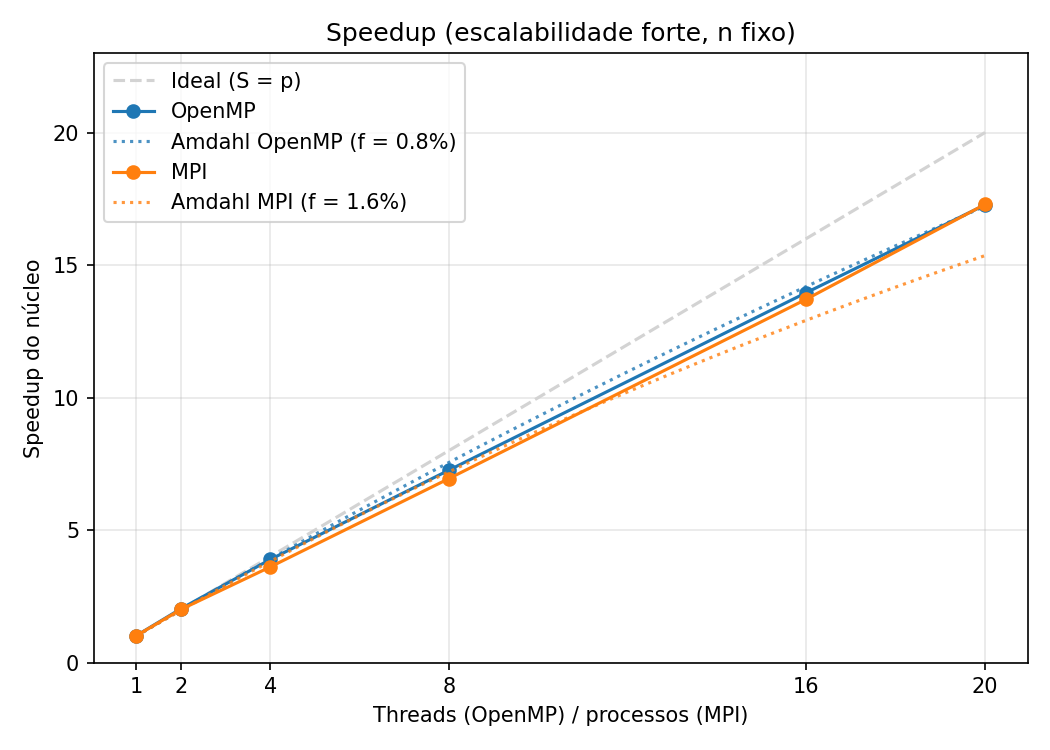

In [ ]:
# @title
# Imagem original incorporada ao notebook. Execute a célula para exibi-la novamente.
from IPython.display import display, Image
import base64
imagem_png = '...'
display(Image(data=base64.b64decode(imagem_png)))


O gráfico compara o ganho de cada versão com o sequencial e com o ganho ideal. As curvas se aproximam da referência ideal, mas ficam abaixo dela nas configurações maiores: com 20 trabalhadores, os speedups são 17,27 para OpenMP e 17,29 para MPI. O ajuste de Amdahl representa uma fração efetiva calculada a partir desses tempos de núcleo.

### Eficiência

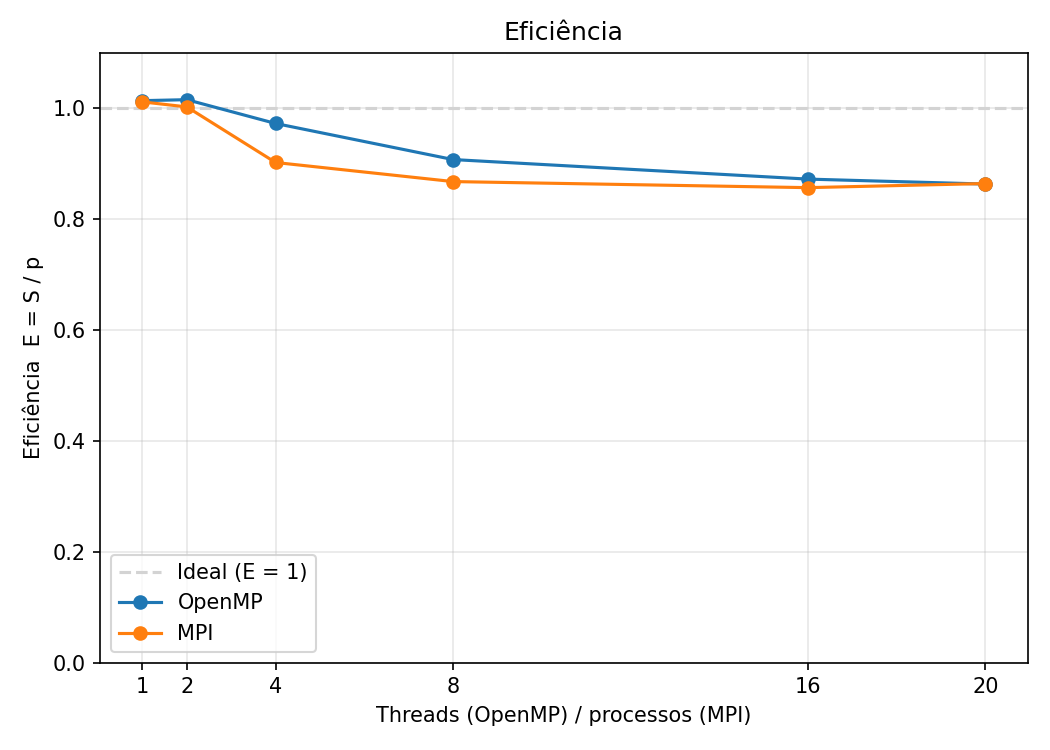

In [ ]:
# @title
# Imagem original incorporada ao notebook. Execute a célula para exibi-la novamente.
from IPython.display import display, Image
import base64
imagem_png = '...'
display(Image(data=base64.b64decode(imagem_png)))


A eficiência relaciona o speedup ao número de trabalhadores. Ela diminui conforme o paralelismo aumenta e chega a aproximadamente 86% nas duas versões com 20 trabalhadores. Custos de sincronização, reduções, comunicação e acesso à memória podem contribuir para essa perda, mas o experimento não mede essas parcelas separadamente.

### Leitura e núcleo

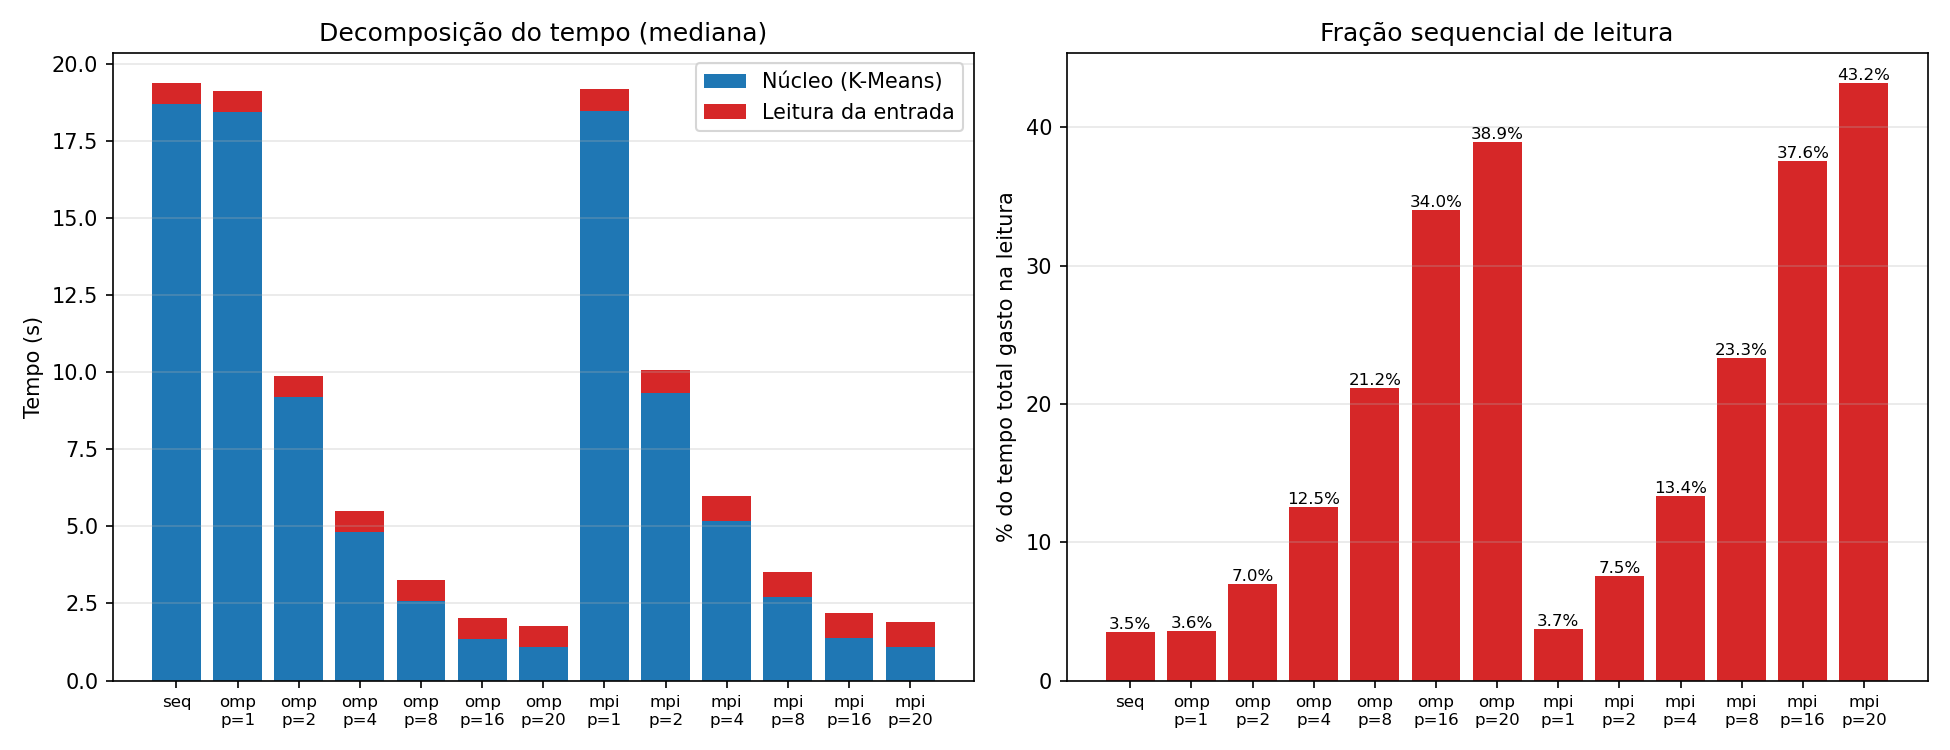

In [ ]:
# @title
# Imagem original incorporada ao notebook. Execute a célula para exibi-la novamente.
from IPython.display import display, Image
import base64
imagem_png = '...'
display(Image(data=base64.b64decode(imagem_png)))


As barras mostram como os intervalos de leitura e de núcleo contribuem para a soma medida. À medida que o núcleo fica mais rápido, a leitura e a preparação passam a representar uma parcela maior dessa soma. No MPI, o intervalo chamado leitura inclui também a distribuição dos pontos e a sincronização inicial; ele não é apenas o tempo de leitura de arquivo.

### Dados originais das medições

Os dados abaixo estão incluídos integralmente para consulta, sem necessidade de executar células. Cada linha contém versão, número de trabalhadores `p`, repetição, tempo de leitura/preparação e tempo do núcleo, em segundos.

<details><summary>Benchmark principal: 65 medições</summary>

```csv
versao,p,rep,leitura,nucleo
seq,1,1,0.6860,18.6782
omp,1,1,0.6924,18.4401
omp,2,1,0.6887,9.1949
omp,4,1,0.6893,4.8138
omp,8,1,0.6901,2.5748
omp,16,1,0.6901,1.3453
omp,20,1,0.6901,1.0807
mpi,1,1,0.7119,18.4984
mpi,2,1,0.7603,9.3240
mpi,4,1,0.8144,5.1801
mpi,8,1,0.8209,2.6928
mpi,16,1,0.8175,1.3636
mpi,20,1,0.8256,1.0822
seq,1,2,0.6842,18.6983
omp,1,2,0.6891,18.4418
omp,2,2,0.6885,9.2040
omp,4,2,0.6893,4.7331
omp,8,2,0.6917,2.5870
omp,16,2,0.6886,1.3388
omp,20,2,0.6895,1.0830
mpi,1,2,0.7107,18.4776
mpi,2,2,0.7591,9.3229
mpi,4,2,0.7856,5.1727
mpi,8,2,0.8220,2.6965
mpi,16,2,0.8219,1.3483
mpi,20,2,0.8193,1.1183
seq,1,3,0.6850,19.4675
omp,1,3,0.6883,18.4340
omp,2,3,0.6883,9.2099
omp,4,3,0.6885,4.8052
omp,8,3,0.6882,2.5719
omp,16,3,0.6900,1.3395
omp,20,3,0.6904,1.0840
mpi,1,3,0.7141,18.4811
mpi,2,3,0.7114,9.3185
mpi,4,3,0.7991,5.1758
mpi,8,3,0.8186,2.6900
mpi,16,3,0.8208,1.4087
mpi,20,3,0.8437,1.0815
seq,1,4,0.6883,18.6907
omp,1,4,0.6890,18.4372
omp,2,4,0.6873,9.2145
omp,4,4,0.6876,4.6252
omp,8,4,0.6911,2.5817
omp,16,4,0.6876,1.3386
omp,20,4,0.6916,1.0827
mpi,1,4,0.7109,18.4803
mpi,2,4,0.7374,9.7630
mpi,4,4,0.8162,5.1853
mpi,8,4,0.8180,2.7177
mpi,16,4,0.8209,1.3502
mpi,20,4,0.8231,1.0805
seq,1,5,0.6898,18.7236
omp,1,5,0.6894,18.4429
omp,2,5,0.6884,9.2028
omp,4,5,0.6896,4.8101
omp,8,5,0.6907,2.5749
omp,16,5,0.6903,1.3439
omp,20,5,0.6932,1.0805
mpi,1,5,0.7143,18.4735
mpi,2,5,0.7605,9.3282
mpi,4,5,0.7857,5.1802
mpi,8,5,0.8165,2.6899
mpi,16,5,0.8222,1.3646
mpi,20,5,0.8187,1.0806
```
</details>

## 6. Conclusão

A estratégia de particionamento por pontos permite paralelizar com eficácia a etapa de atribuição dentro de cada iteração do K-Means. Enquanto a implementação em OpenMP consolida as somas parciais diretamente em memória compartilhada, a abordagem em MPI distribui os subconjuntos de dados entre os processos e recorre a operações coletivas para sincronizar e atualizar os centroides globalmente. Nos experimentos avaliados, ambas as versões reduziram o tempo de execução do núcleo computacional até o limite de $p = 20$ trabalhadores, embora a eficiência paralela tenha permanecido abaixo do ganho linear ideal.

Na análise desses resultados, é importante considerar algumas limitações de escopo:

* As métricas de desempenho refletem exclusivamente o conjunto de entrada e a configuração de hardware utilizados na coleta original; a demonstração executada neste notebook serve apenas para validar o comportamento funcional em pequena escala e não substitui os testes no cluster.
* As implementações em OpenMP e MPI possuem divergências sutis na forma como tratam a ocorrência de clusters vazios durante as iterações.
* Os logs de tempo disponíveis não isolam a parcela gasta estritamente com comunicação e sincronização.

### Referências

* Documentação de estrutura e uso do cluster OpenHPC da UFSCar: https://gitlab.com/ufscar/hpc/documentacao/-/wikis/usuario#estrutura-cluster
* Enunciado do Problema D da 12ª Maratona de Programação Paralela (SBAC-PAD & WSCAD, 2017).